In [23]:
import matplotlib.pyplot as plt
from pathlib import Path
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, sum, count, when

In [24]:
spark = SparkSession.builder \
    .appName("Goodreads_Interactions") \
    .config("spark.driver.memory", "8g") \
    .getOrCreate()

In [25]:
# DIR = Path.cwd().parent / 'data'
# df_interactions = spark.read.csv(str(DIR / 'goodreads_interactions.csv'), header=True, inferSchema=True)

In [26]:
DIR = Path.cwd().parent / 'samples_data'
df_interactions = spark.read.parquet(str(DIR / 'interactions'))

In [27]:
duplicates = df_interactions.groupBy('user_id', 'book_id').count().select('user_id', 'book_id', (col('count') - 1).alias('duplicate_count'))
duplicates.show()

+-------+-------+---------------+
|user_id|book_id|duplicate_count|
+-------+-------+---------------+
| 807859| 314065|              0|
| 679714| 782025|              0|
| 704522| 664094|              0|
| 807022|  46423|              0|
| 661148| 393623|              0|
| 671263| 344020|              0|
| 802701| 765816|              0|
| 680039|  17647|              0|
| 768586|  17647|              0|
| 806845|  17647|              0|
| 663646|   1415|              0|
| 681457|   1415|              0|
| 670322| 122564|              0|
| 678374| 283345|              0|
| 714946| 126121|              0|
| 646620|  39414|              0|
| 831375|  39414|              0|
| 778634|1376760|              0|
| 718071|  78962|              0|
| 673247|2349616|              0|
+-------+-------+---------------+
only showing top 20 rows


In [28]:
stats = df_interactions.select(
    count("*").alias("# shelve"),
    sum("is_read").alias("# read"),
    sum(when(col("rating") > 0, 1).otherwise(0)).alias("# rate"),
    sum("is_reviewed").alias("# review")
)
stats.show()

+--------+------+------+--------+
|# shelve|# read|# rate|# review|
+--------+------+------+--------+
| 1007018|518373|487320|   63344|
+--------+------+------+--------+



In [29]:
rating_dist = df_interactions.groupBy('rating').count().orderBy('count', ascending=False)
rating_dist.show()

+------+------+
|rating| count|
+------+------+
|     0|519698|
|     4|177413|
|     5|155810|
|     3|113813|
|     2| 30597|
|     1|  9687|
+------+------+



In [30]:
def get_distribution(df, entity_col, filter_condition=None):
    if filter_condition is not None:
        df_filtered = df.filter(filter_condition)
    else:
        df_filtered = df
        
    interaction_count = df_filtered.groupBy(entity_col).count().withColumnRenamed('count', 'num_interactions')
    distribution = interaction_count.groupBy('num_interactions').count().orderBy('num_interactions')
    
    return distribution.toPandas()

pdf_shelve_user = get_distribution(df_interactions, 'user_id')
pdf_read_user = get_distribution(df_interactions, 'user_id', col('is_read') > 0)
pdf_rate_user = get_distribution(df_interactions, 'user_id', col('rating') > 0)
pdf_review_user = get_distribution(df_interactions, 'user_id', col('is_reviewed') > 0)

pdf_shelve_book = get_distribution(df_interactions, 'book_id')
pdf_read_book = get_distribution(df_interactions, 'book_id', col('is_read') > 0)
pdf_rate_book = get_distribution(df_interactions, 'book_id', col('rating') > 0)
pdf_review_book = get_distribution(df_interactions, 'book_id', col('is_reviewed') > 0)

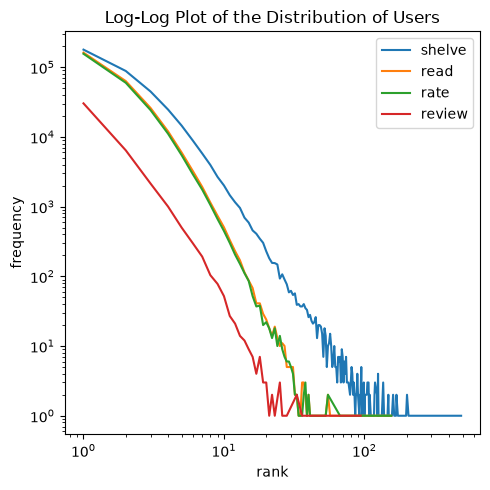

In [31]:
plt.figure(figsize=(5, 5))
plt.loglog(pdf_shelve_user['num_interactions'], pdf_shelve_user['count'], label='shelve')
plt.loglog(pdf_read_user['num_interactions'], pdf_read_user['count'], label='read')
plt.loglog(pdf_rate_user['num_interactions'], pdf_rate_user['count'], label='rate')
plt.loglog(pdf_review_user['num_interactions'], pdf_review_user['count'], label='review')
plt.xlabel('rank')
plt.ylabel('frequency')
plt.title('Log-Log Plot of the Distribution of Users')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

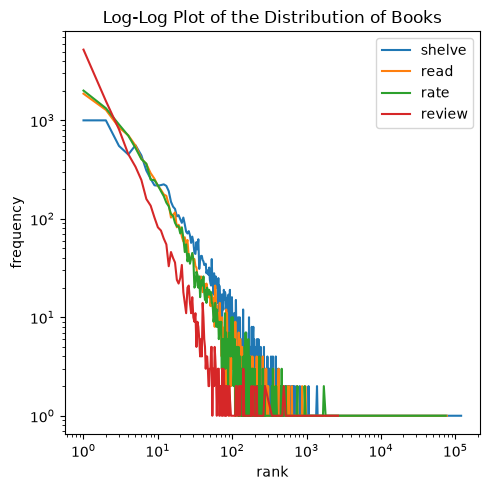

In [32]:
plt.figure(figsize=(5, 5))
plt.loglog(pdf_shelve_book['num_interactions'], pdf_shelve_book['count'], label='shelve')
plt.loglog(pdf_read_book['num_interactions'], pdf_read_book['count'], label='read')
plt.loglog(pdf_rate_book['num_interactions'], pdf_rate_book['count'], label='rate')
plt.loglog(pdf_review_book['num_interactions'], pdf_review_book['count'], label='review')
plt.xlabel('rank')
plt.ylabel('frequency')
plt.title('Log-Log Plot of the Distribution of Books')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()